Environment Setup and Dataset Path

In [1]:
import os
import glob
import cv2
import numpy as np
import matplotlib.pyplot as plt

DATASET_DIR = "/content/drive/MyDrive/datasets/Skin cancer ISIC The International Skin Imaging Collaboration"

# Automatically find 5 sample lesion images across classes
image_paths = glob.glob(os.path.join(DATASET_DIR, "**", "*.jpg"), recursive=True)
if not image_paths:
    image_paths = glob.glob(os.path.join(DATASET_DIR, "**", "*.png"), recursive=True)

# Select first 5 images for the batch assignment requirements
selected_images = image_paths[:5]
print(f"Found {len(image_paths)} images. Selected 5 images for evaluation:")
for idx, path in enumerate(selected_images, 1):
    print(f"Image {idx}: {path}")

Found 2357 images. Selected 5 images for evaluation:
Image 1: /content/drive/MyDrive/datasets/Skin cancer ISIC The International Skin Imaging Collaboration/Test/actinic keratosis/ISIC_0010512.jpg
Image 2: /content/drive/MyDrive/datasets/Skin cancer ISIC The International Skin Imaging Collaboration/Test/actinic keratosis/ISIC_0010889.jpg
Image 3: /content/drive/MyDrive/datasets/Skin cancer ISIC The International Skin Imaging Collaboration/Test/actinic keratosis/ISIC_0024468.jpg
Image 4: /content/drive/MyDrive/datasets/Skin cancer ISIC The International Skin Imaging Collaboration/Test/actinic keratosis/ISIC_0024511.jpg
Image 5: /content/drive/MyDrive/datasets/Skin cancer ISIC The International Skin Imaging Collaboration/Test/actinic keratosis/ISIC_0024470.jpg


Tasks 1 to 6 Implementation on a Single Lesion Image

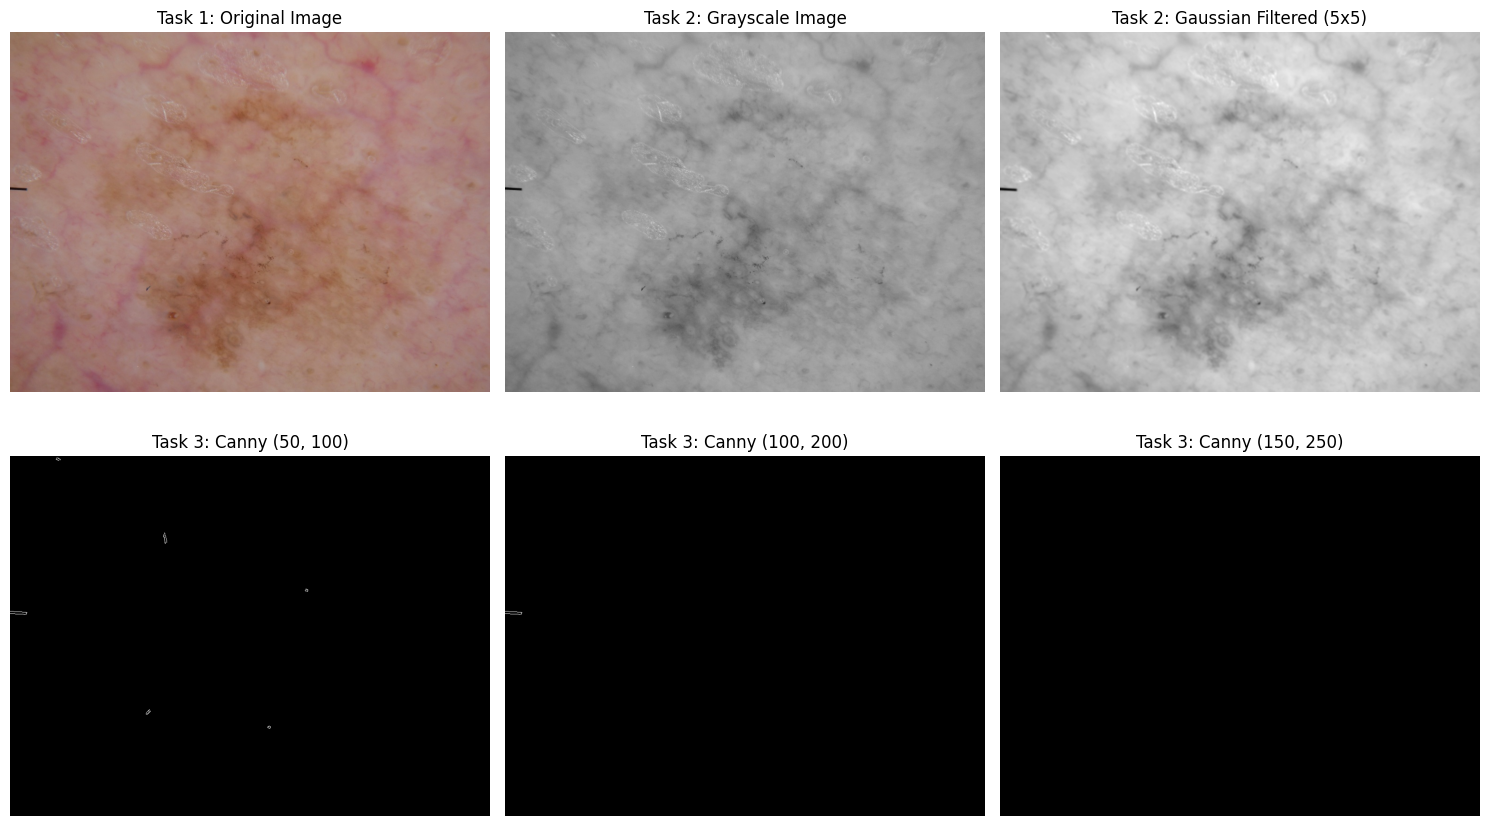

Task 4 Selection: Selected Threshold (100, 200) as it best balances boundary continuity without capturing excessive skin texture noise.
Task 6 Results:
  Lesion Area     : 166.50 pixels
  Lesion Perimeter: 81.90 pixels


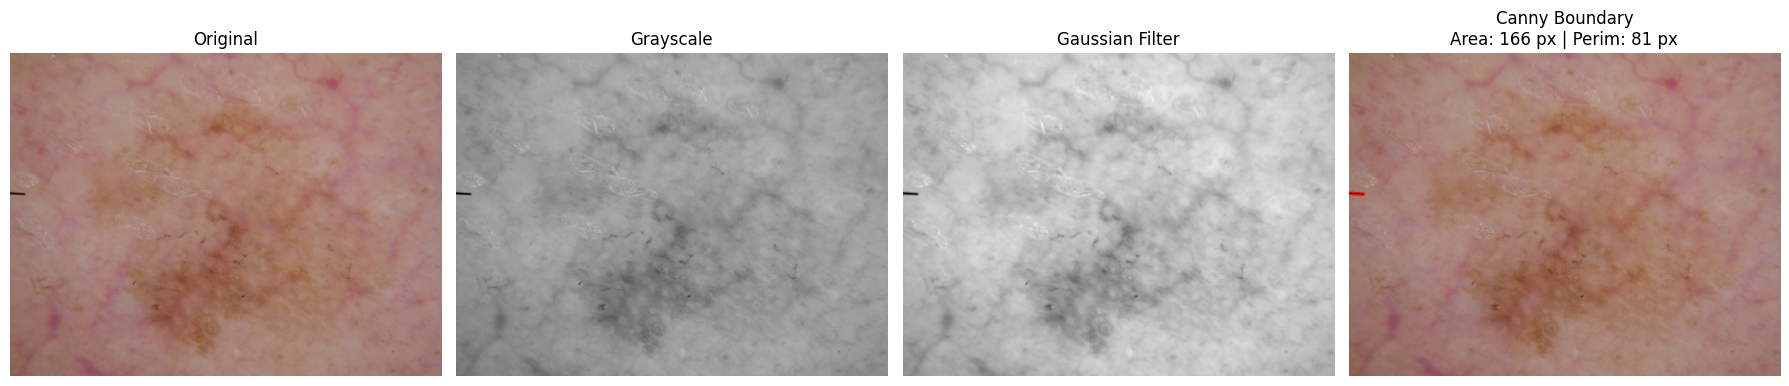

In [2]:
# Select the primary image for Tasks 1-6 demonstration
sample_path = selected_images[0]

# --- Task 1: Load the Image ---
img_bgr = cv2.imread(sample_path)
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

# --- Task 2: Preprocess the Image ---
img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
# Apply Gaussian filter with a 5x5 kernel and sigma=1.4 to suppress skin textures/artifacts
img_gaussian = cv2.GaussianBlur(img_gray, (5, 5), 1.4)

# --- Task 3: Apply Canny Edge Detection with 3 Threshold Settings ---
canny_t1 = cv2.Canny(img_gaussian, 50, 100)
canny_t2 = cv2.Canny(img_gaussian, 100, 200)
canny_t3 = cv2.Canny(img_gaussian, 150, 250)

# Display Tasks 1, 2, and 3
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes[0, 0].imshow(img_rgb)
axes[0, 0].set_title("Task 1: Original Image")
axes[0, 0].axis("off")

axes[0, 1].imshow(img_gray, cmap="gray")
axes[0, 1].set_title("Task 2: Grayscale Image")
axes[0, 1].axis("off")

axes[0, 2].imshow(img_gaussian, cmap="gray")
axes[0, 2].set_title("Task 2: Gaussian Filtered (5x5)")
axes[0, 2].axis("off")

axes[1, 0].imshow(canny_t1, cmap="gray")
axes[1, 0].set_title("Task 3: Canny (50, 100)")
axes[1, 0].axis("off")

axes[1, 1].imshow(canny_t2, cmap="gray")
axes[1, 1].set_title("Task 3: Canny (100, 200)")
axes[1, 1].axis("off")

axes[1, 2].imshow(canny_t3, cmap="gray")
axes[1, 2].set_title("Task 3: Canny (150, 250)")
axes[1, 2].axis("off")

plt.tight_layout()
plt.show()

# --- Task 4: Select the Best Result ---
# (100, 200) balances edge connectivity while filtering spurious micro-skin lines
best_canny = canny_t2.copy()
print("Task 4 Selection: Selected Threshold (100, 200) as it best balances boundary continuity without capturing excessive skin texture noise.")

# --- Task 5: Detect the Lesion Boundary Using Morphological Operations & Contours ---
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
# Close small gaps in the boundary
closed_edges = cv2.morphologyEx(best_canny, cv2.MORPH_CLOSE, kernel, iterations=2)

# Find external contours
contours, _ = cv2.findContours(closed_edges, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

boundary_img = img_rgb.copy()
lesion_contour = None
area = 0
perimeter = 0

if contours:
    # The lesion corresponds to the largest enclosed boundary
    lesion_contour = max(contours, key=cv2.contourArea)
    cv2.drawContours(boundary_img, [lesion_contour], -1, (255, 0, 0), 2)  # Red contour

    # --- Task 6: Calculate Lesion Area & Perimeter ---
    area = cv2.contourArea(lesion_contour)
    perimeter = cv2.arcLength(lesion_contour, closed=True)

print(f"Task 6 Results:")
print(f"  Lesion Area     : {area:.2f} pixels")
print(f"  Lesion Perimeter: {perimeter:.2f} pixels")

# --- Required Final Pipeline Visualization ---
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
axes[0].imshow(img_rgb)
axes[0].set_title("Original")
axes[0].axis("off")

axes[1].imshow(img_gray, cmap="gray")
axes[1].set_title("Grayscale")
axes[1].axis("off")

axes[2].imshow(img_gaussian, cmap="gray")
axes[2].set_title("Gaussian Filter")
axes[2].axis("off")

axes[3].imshow(boundary_img)
axes[3].set_title(f"Canny Boundary\nArea: {int(area)} px | Perim: {int(perimeter)} px")
axes[3].axis("off")

plt.tight_layout()
plt.show()

Processing 5 Images for Table 1

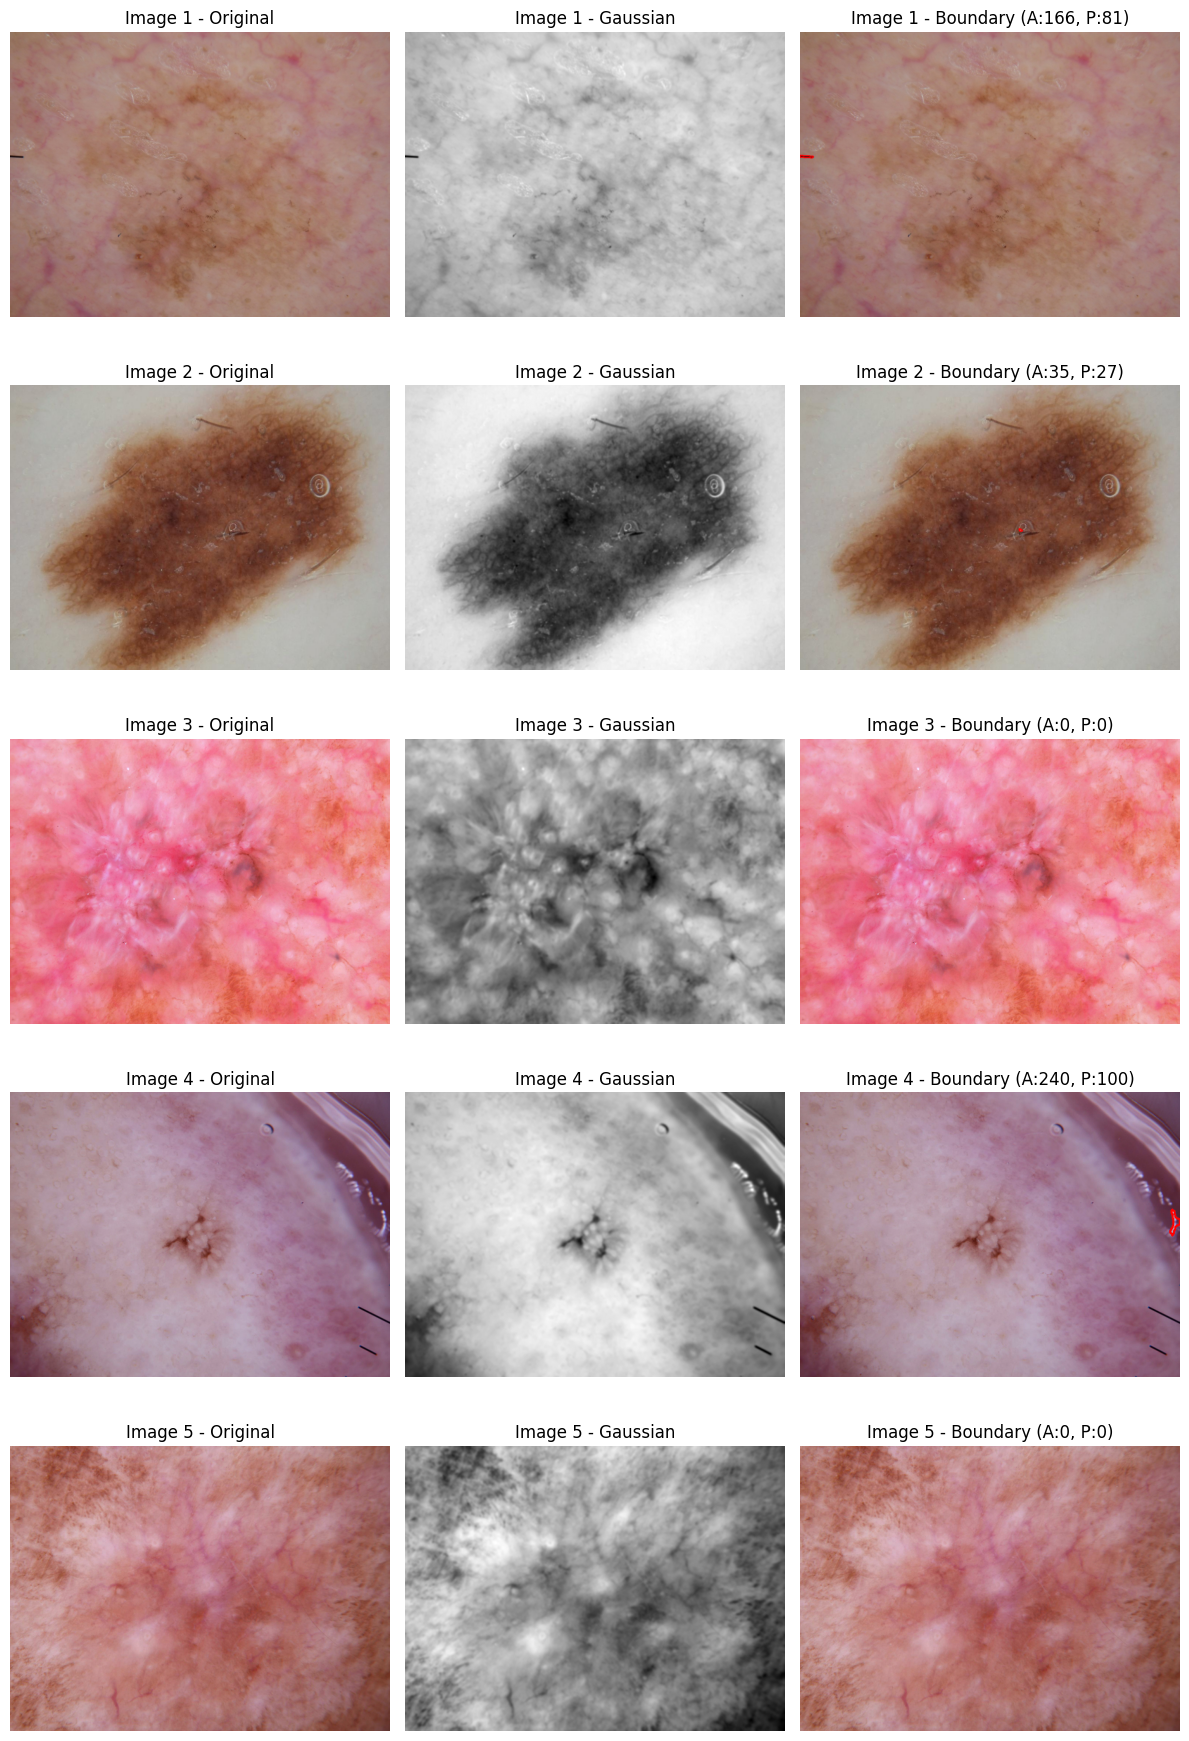


--- Extracted Data for Table 1 ---
  Image    Best Filter      Edge Method  Area (pixels)  Perimeter (pixels)
Image 1 Gaussian (5x5) Canny (100, 200)          166.5               81.90
Image 2 Gaussian (5x5) Canny (100, 200)           35.5               27.56
Image 3 Gaussian (5x5) Canny (100, 200)            0.0                0.00
Image 4 Gaussian (5x5) Canny (100, 200)          240.0              100.43
Image 5 Gaussian (5x5) Canny (100, 200)            0.0                0.00


In [3]:
def process_lesion_image(image_path, canny_low=100, canny_high=200):
    bgr = cv2.imread(image_path)
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    filtered = cv2.GaussianBlur(gray, (5, 5), 1.4)
    edges = cv2.Canny(filtered, canny_low, canny_high)

    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
    closed = cv2.morphologyEx(edges, cv2.MORPH_CLOSE, kernel, iterations=2)
    contours, _ = cv2.findContours(closed, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    boundary_display = rgb.copy()
    area, perimeter = 0.0, 0.0
    if contours:
        largest_c = max(contours, key=cv2.contourArea)
        cv2.drawContours(boundary_display, [largest_c], -1, (255, 0, 0), 2)
        area = cv2.contourArea(largest_c)
        perimeter = cv2.arcLength(largest_c, closed=True)

    return rgb, filtered, boundary_display, area, perimeter

table_1_records = []
fig, axes = plt.subplots(5, 3, figsize=(12, 18))

for i, path in enumerate(selected_images):
    orig, filt, bound, a, p = process_lesion_image(path)
    label = f"Image {i+1}"
    table_1_records.append({
        "Image": label,
        "Best Filter": "Gaussian (5x5)",
        "Edge Method": "Canny (100, 200)",
        "Area (pixels)": round(a, 2),
        "Perimeter (pixels)": round(p, 2)
    })

    axes[i, 0].imshow(orig)
    axes[i, 0].set_title(f"{label} - Original")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(filt, cmap="gray")
    axes[i, 1].set_title(f"{label} - Gaussian")
    axes[i, 1].axis("off")

    axes[i, 2].imshow(bound)
    axes[i, 2].set_title(f"{label} - Boundary (A:{int(a)}, P:{int(p)})")
    axes[i, 2].axis("off")

plt.tight_layout()
plt.show()

import pandas as pd
df_table1 = pd.DataFrame(table_1_records)
print("\n--- Extracted Data for Table 1 ---")
print(df_table1.to_string(index=False))

Filter and Edge Comparison Experiment for Table 2

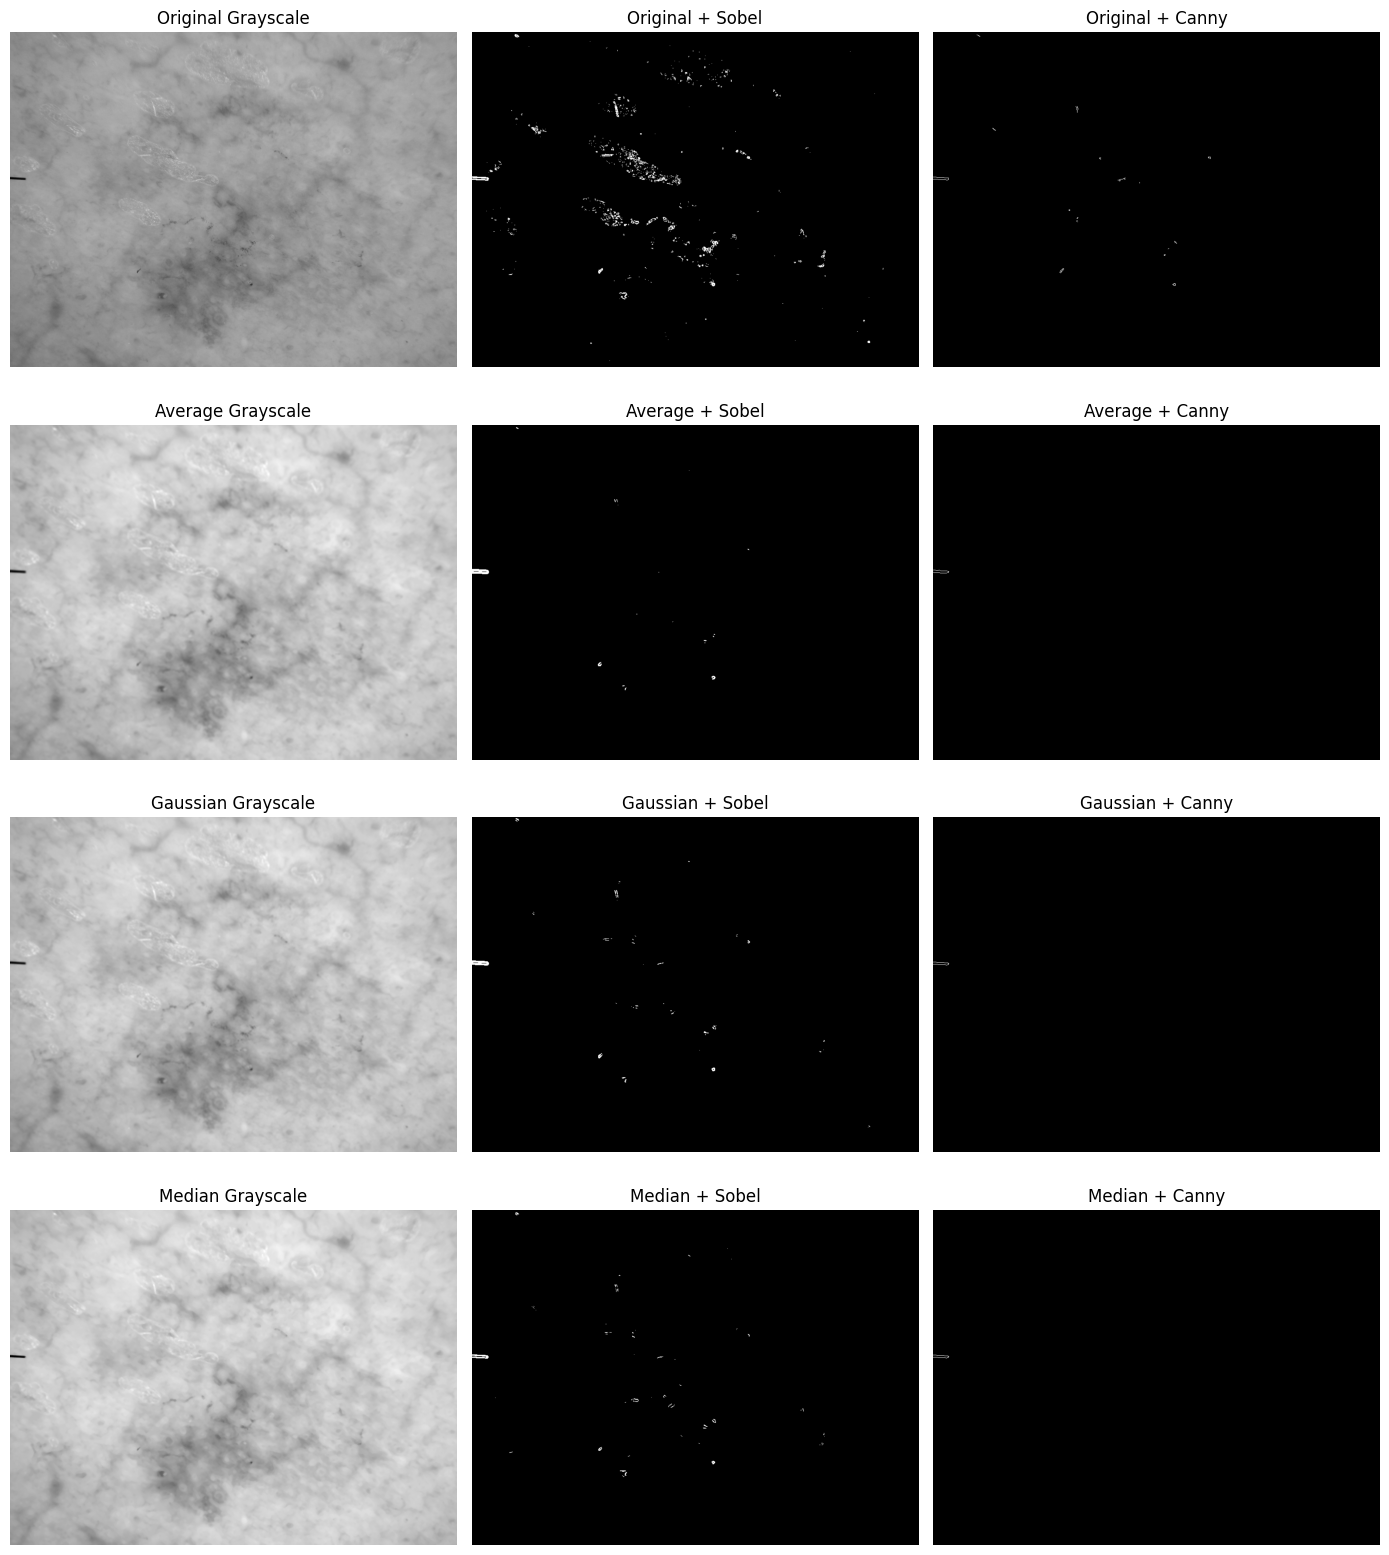

In [4]:
def compute_sobel(gray_img):
    grad_x = cv2.Sobel(gray_img, cv2.CV_64F, 1, 0, ksize=3)
    grad_y = cv2.Sobel(gray_img, cv2.CV_64F, 0, 1, ksize=3)
    magnitude = cv2.magnitude(grad_x, grad_y)
    sobel_edges = np.uint8(np.clip(magnitude, 0, 255))
    _, binary_sobel = cv2.threshold(sobel_edges, 50, 255, cv2.THRESH_BINARY)
    return binary_sobel

# Prepare filter variants on the primary grayscale image
filters = {
    "Original": img_gray,
    "Average": cv2.blur(img_gray, (5, 5)),
    "Gaussian": cv2.GaussianBlur(img_gray, (5, 5), 1.4),
    "Median": cv2.medianBlur(img_gray, 5)
}

fig, axes = plt.subplots(4, 3, figsize=(14, 16))

row = 0
for filt_name, filtered_img in filters.items():
    sobel_res = compute_sobel(filtered_img)
    canny_res = cv2.Canny(filtered_img, 100, 200)

    axes[row, 0].imshow(filtered_img, cmap="gray")
    axes[row, 0].set_title(f"{filt_name} Grayscale")
    axes[row, 0].axis("off")

    axes[row, 1].imshow(sobel_res, cmap="gray")
    axes[row, 1].set_title(f"{filt_name} + Sobel")
    axes[row, 1].axis("off")

    axes[row, 2].imshow(canny_res, cmap="gray")
    axes[row, 2].set_title(f"{filt_name} + Canny")
    axes[row, 2].axis("off")

    row += 1

plt.tight_layout()
plt.show()